# Analisi iniziale dei dati

## Evoluzione delle anime negli anni

In [33]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px

In [34]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
import pycountry
from plotly.subplots import make_subplots

In [35]:
# load dataset
df_details = pd.read_csv("../../dataset/cleaned/details_cleaned.csv")
df_favs = pd.read_csv("../../dataset/cleaned/favs_cleaned.csv")
df_recommendations = pd.read_csv("../../dataset/cleaned/recommendations_cleaned.csv")
df_stats = pd.read_csv("../../dataset/cleaned/stats_cleaned.csv")
df_ratings = pd.read_csv("../../dataset/cleaned/ratings_cleaned.csv")


In [36]:
df_details['start_date'] = pd.to_datetime(df_details['start_date'], errors='coerce')
df_details['year'] = df_details['start_date'].dt.year.astype("Int64")
df_details['scored_by'] = pd.to_numeric(df_details['scored_by'], errors='coerce')

In [37]:
# load dataset
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")
df_characters_anime_works = pd.read_csv("../../dataset/cleaned/character_anime_works_cleaned.csv")
df_person_voice_works = pd.read_csv("../../dataset/cleaned/person_voice_works_cleaned.csv")
df_characters = pd.read_csv("../../dataset/cleaned/characters_cleaned.csv")

In [38]:
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")

df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")

### Nella prima parte viene presentata un’analisi temporale della produzione, utile a contestualizzare storicamente il fenomeno. Le sezioni successive approfondiscono aspetti legati alla popolarità, ai rating degli utenti e alle fonti di ispirazione

In [39]:
details = df_details.copy()
details = details.dropna(subset=['start_date'])

# Conteggio anime per anno
counts = (details['year'].value_counts().sort_index().reset_index())
counts.columns = ['year', 'anime_count']

fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Dagli anni ’70 in poi si osserva una **crescita** quasi **esponenziale** del numero di anime prodotti, con un’accelerazione marcata dopo il 2000.
Negli ultimi anni, invece, il trend mostra oscillazioni e un leggero **calo**, suggerendo una possibile fase di saturazione del mercato.

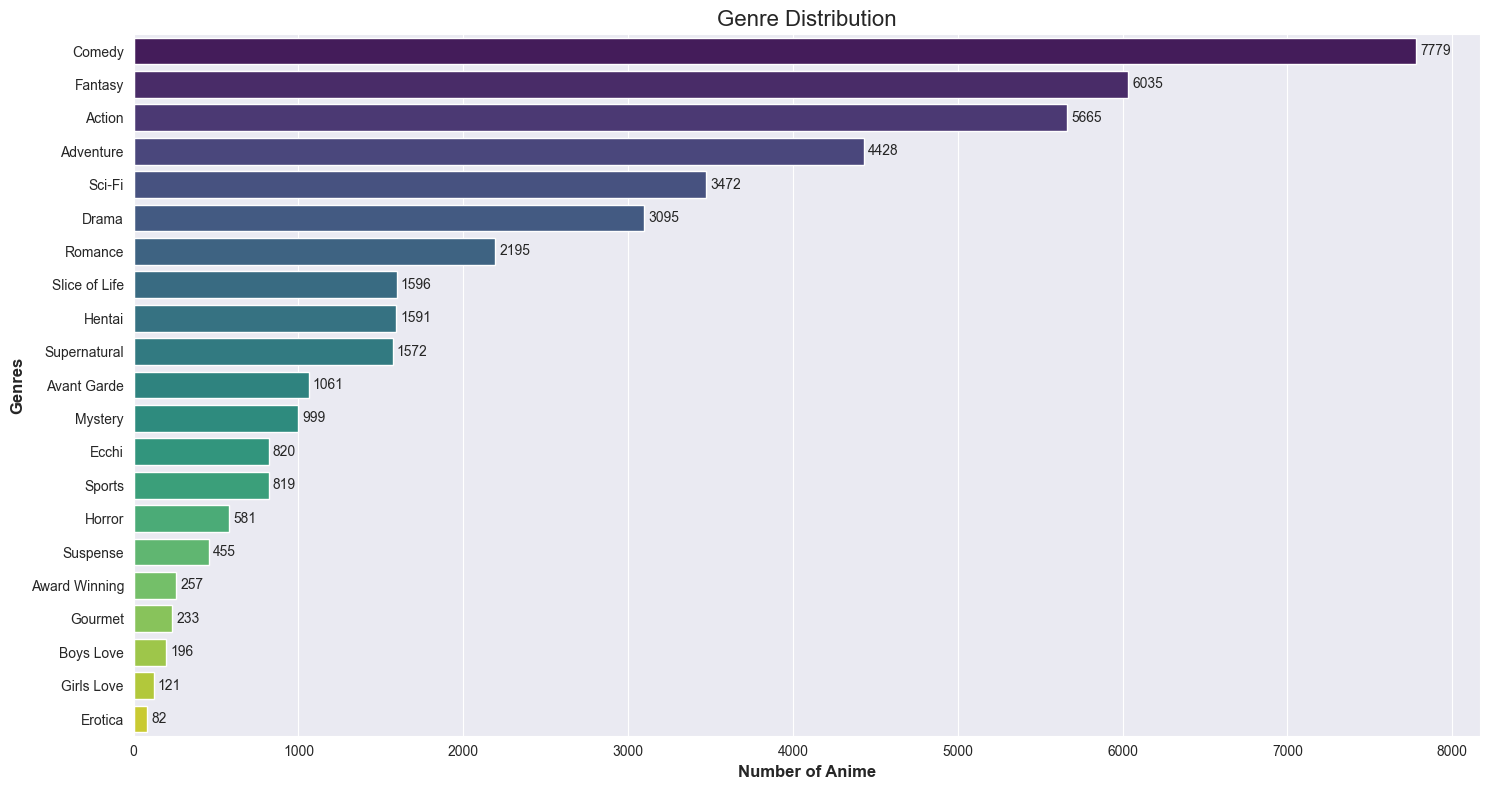

In [40]:
df_genres = df_details['genres'].copy()
df_genres = df_genres.apply(ast.literal_eval)

df_genres = df_genres.explode().dropna()
genre_count = df_genres.value_counts().reset_index()

genre_count.columns = ['genre', 'count']
# plot
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Genre Distribution', fontsize=16)
plt.xlabel('Number of Anime', fontsize=12, fontweight='bold')
plt.ylabel('Genres', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## Evoluzione dei principali generi anime nel tempo

### Come cambiano i generi anime dal 1917 a oggi

In [41]:
def parse_genres(x):
    if isinstance(x, list):
        return x
    try:
        return ast.literal_eval(x)
    except:
        return []

In [42]:
df_gen_evol = df_details.copy()
df_gen_evol = df_gen_evol.dropna(subset=['year'])

df_gen_evol = df_gen_evol[(df_gen_evol['year'] >= 1917) & (df_gen_evol['year'] <= 2024)]
df_gen_evol = df_gen_evol.dropna(subset=['genres'])
df_gen_evol['genres'] = df_gen_evol['genres'].apply(parse_genres)
df_gen_evol['genres'] = df_gen_evol['genres'].apply(lambda g: [gen.strip().title() for gen in g])

# explode generi
genres_df = df_gen_evol.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible='legendonly'
        )
    )
fig.update_layout(
    title="Anime production over time by genre",
    xaxis_title="Year",
    yaxis_title="Number of anime released",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Click genres to show / hide"
)
fig.show()

Questo grafico mostra l’evoluzione dei principali generi anime nel tempo, evidenziando come la crescita dell’industria sia stata accompagnata da una progressiva specializzazione dei contenuti.

Fino agli anni ’80 la produzione è limitata e relativamente omogenea, mentre a partire dagli anni ’90 emergono differenze sempre più marcate tra i generi.

Dopo il 2000 si osserva una forte espansione di generi come **Action**, **Fantasy** e **Comedy**, riflettendo l’ampliamento del pubblico e la diversificazione dei gusti.

Negli anni più recenti alcune curve mostrano una stabilizzazione o una lieve flessione, suggerendo una fase di assestamento del mercato più che una diminuzione di interesse

#### Ok, abbiamo visto come cambiano le cose nel tempo. Ora guardiamo com’è fatto l’ecosistema complessivo.

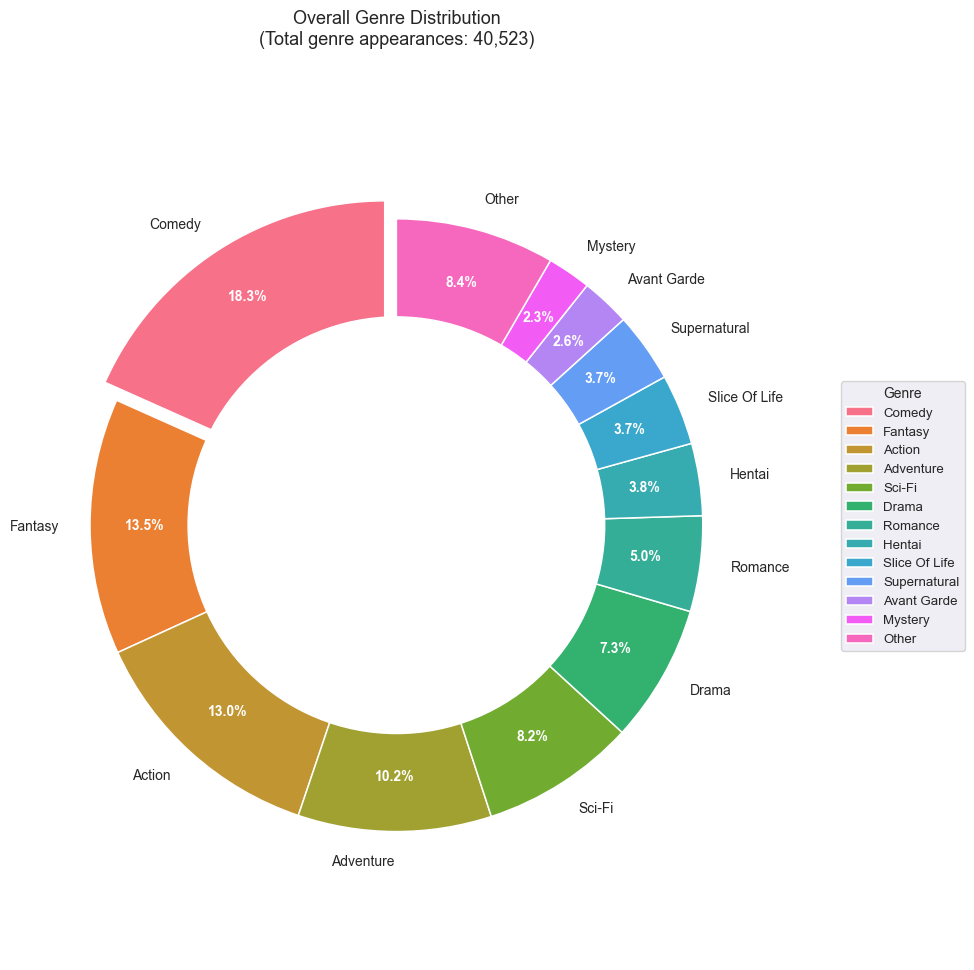

In [43]:
# conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()
# numeri di generi principali da mostrare singolarmente nel pie
top_n_pie = 12
# prendiamo solo i primi N generi più frequentati
top_genres_pie = genre_total.head(top_n_pie)
# sommiamo tutti i generi rimnenti , ciè dal 13 e in poi
other_count = genre_total.iloc[top_n_pie:].sum()
# creiamo la categoria "other"
if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie
# creazione grafico
plt.figure(figsize=(10, 10))
colors = sns.color_palette("husl", len(pie_data))
# explode solo sulla fetta più frequente
explode = [0.07 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]
# disegno pie chart
wedges, texts, autotexts = plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},
    textprops={'fontsize': 10}
)
# stile delle percentuali
for autotext in autotexts:autotext.set_color('white'), autotext.set_fontweight('bold')
# titoli
plt.title(f"Overall Genre Distribution\n(Total genre appearances: {genre_total.sum():,})",fontsize=13, pad=20)
# cerchio centrale per effetto 'donut'
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# legenda
plt.legend(pie_data.index,title="Genre",loc="center left",bbox_to_anchor=(1.15, 0.5),fontsize=9.5)

plt.axis('equal')
plt.tight_layout()
plt.show()

I risultati evidenziano una forte predominanza di generi orientati all’intrattenimento di massa, come Comedy, Action e Fantasy, che rappresentano una parte significativa della produzione totale.

Accanto a questi, emerge una varietà di generi meno rappresentati che contribuiscono alla diversificazione dell’offerta, suggerendo un ecosistema ricco e stratificato piuttosto che dominato da una singola tendenza.

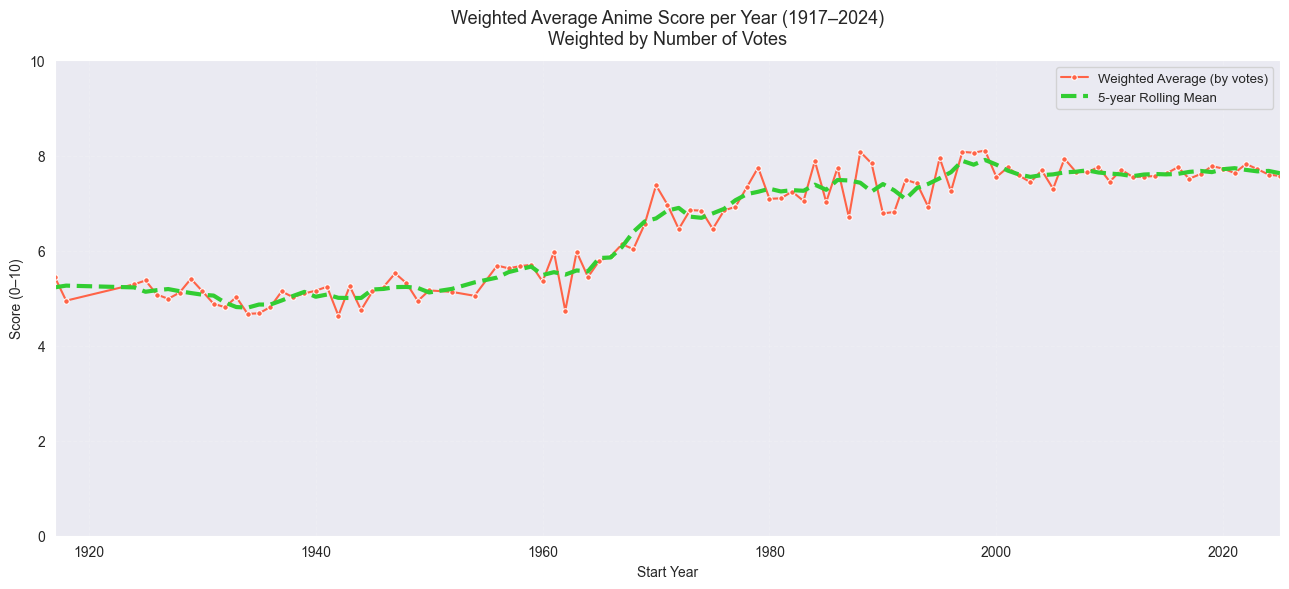

In [44]:
details = df_details.copy()
# filtro per il calcolo della media pesata
df_weighted = details[
    details['score'].notna() &
    details['scored_by'].notna() &
    (details['scored_by'] > 0) &
    details['year'].notna()
].copy()

# limitiamo l'analisi agli anni con dati storicamnete rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]

# calcolo di media dei punteggi, totale dei voti, numero di anime rilasciati
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False
).reset_index()
# Ordina per sicurezza
year_weighted = year_weighted.sort_values('year')
# calcoliamo una media mobile centrata su 5 anni per rendere il trend più leggibile
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(window=5, center=True, min_periods=2).mean()
# visualizzazione
plt.figure(figsize=(13, 6))
# Linea principale: media pesata
sns.lineplot(data=year_weighted,x='year',y='weighted_mean',color='tomato',linewidth=1.5,marker='o',markersize=4,label='Weighted Average (by votes)')
# media mobile
plt.plot(
    year_weighted['year'],
    year_weighted['rolling_weighted'],
    color='limegreen',
    linewidth=3,
    linestyle='--',
    label='5-year Rolling Mean'
)
plt.title("Weighted Average Anime Score per Year (1917–2024)\nWeighted by Number of Votes",fontsize=13,pad=12)
plt.xlabel("Start Year")
plt.ylabel("Score (0–10)")
# limiti degli assi per una scala coerente
plt.xlim(year_weighted['year'].min(), year_weighted['year'].max())
plt.ylim(0, 10)

plt.grid(True, alpha=0.15, linestyle='--')
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.


### I generi più prodotti sono anche quelli più amati dai fan?

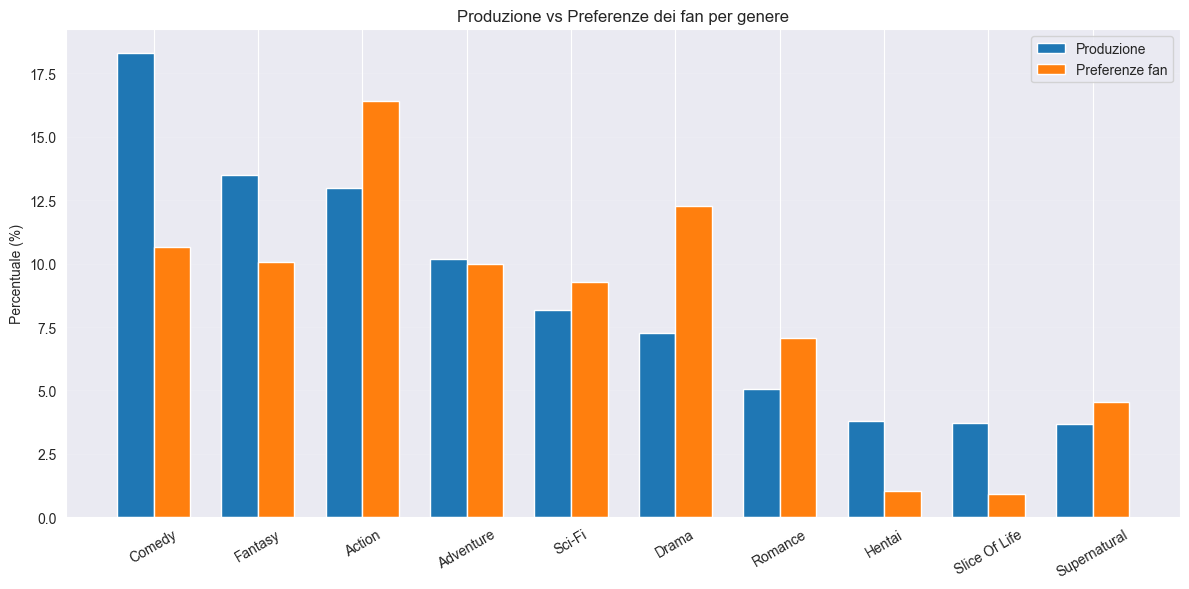

In [45]:
favs = df_favs.copy()
production = genres_df['genres'].value_counts()
production_pct = production / production.sum() * 100

favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
favs_count = favs_genres['genres'].value_counts()
favs_pct = favs_count / favs_count.sum() * 100

compare = pd.DataFrame({'Production (%)': production_pct, 'Fan Preferences (%)': favs_pct}).dropna()
compare = compare.sort_values('Production (%)', ascending=False).head(10)

x = np.arange(len(compare))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, compare['Production (%)'], width, label='Produzione')
plt.bar(x + width / 2, compare['Fan Preferences (%)'], width, label='Preferenze fan', )
plt.xticks(x, compare.index, rotation=30)
plt.ylabel("Percentuale (%)")
plt.title("Produzione vs Preferenze dei fan per genere")
plt.legend()
plt.grid(axis='y', alpha=0.1)
plt.tight_layout()
plt.show()

Il confronto tra la quota di produzione e le preferenze dei fan evidenzia come le strategie dell’industria anime non siano sempre allineate con i gusti del pubblico.
Mentre generi come Action mostrano un equilibrio tra offerta e domanda, altri come Comedy risultano sovra-rappresentati.
Al contrario, generi come Drama e Romance sembrano essere sottovalutati dall’industria nonostante un forte interesse da parte dei fan.

## Da dove nascono gli anime? Le fonti di ispirazione dell’industria

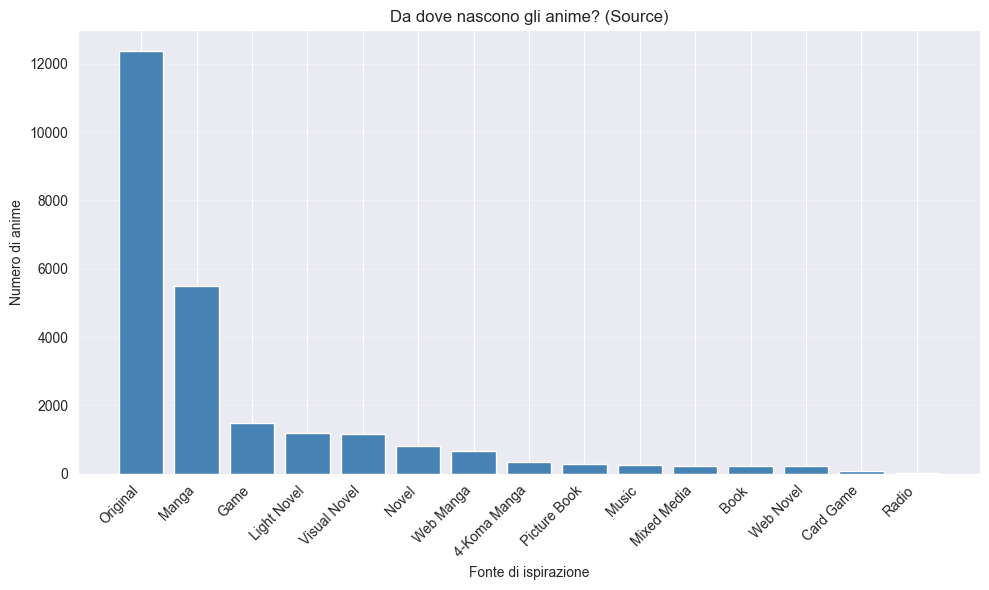

In [46]:
details = df_details.copy()
# filtro categoria unknown
details = details[(details['source'].notna()) & (details['source'] != 'Unknown') & (details['source'] != 'Other')]
details['source'] = details['source'].str.strip().str.title()
source_counts = (details['source'].value_counts().reset_index())
source_counts.columns = ['source', 'count']
# grafico
plt.figure(figsize=(10, 6))
plt.bar(source_counts['source'], source_counts['count'],color='steelblue')

plt.xlabel("Fonte di ispirazione")
plt.ylabel("Numero di anime")
plt.title("Da dove nascono gli anime? (Source)")

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Il grafico mostra la distribuzione delle principali **fonti di ispirazione** degli anime, evidenziando da quali media o opere originali nasce la produzione animata giapponese.

Il dato più evidente è la **forte predominanza delle opere Original**, che rappresentano la quota maggiore. Questo suggerisce che l’industria anime mantiene una notevole capacità creativa autonoma, producendo contenuti non direttamente derivati da altri media.

Subito dopo emergono gli adattamenti da **Manga**, che confermano il ruolo centrale di questo medium come serbatoio narrativo per l’animazione giapponese. Manga e anime risultano quindi profondamente interconnessi, sia dal punto di vista artistico che industriale.

Le altre categorie (come **Light Novel**, **Game**, **Visual Novel** e **Web Manga**) hanno una presenza più contenuta ma significativa, indicando una crescente tendenza alla contaminazione tra media diversi. Questo fenomeno riflette l’evoluzione del consumo culturale, sempre più crossmediale.

Nel complesso, il grafico racconta un’industria che combina **creatività originale** e **adattamento strategico**, bilanciando innovazione e sicurezza commerciale.


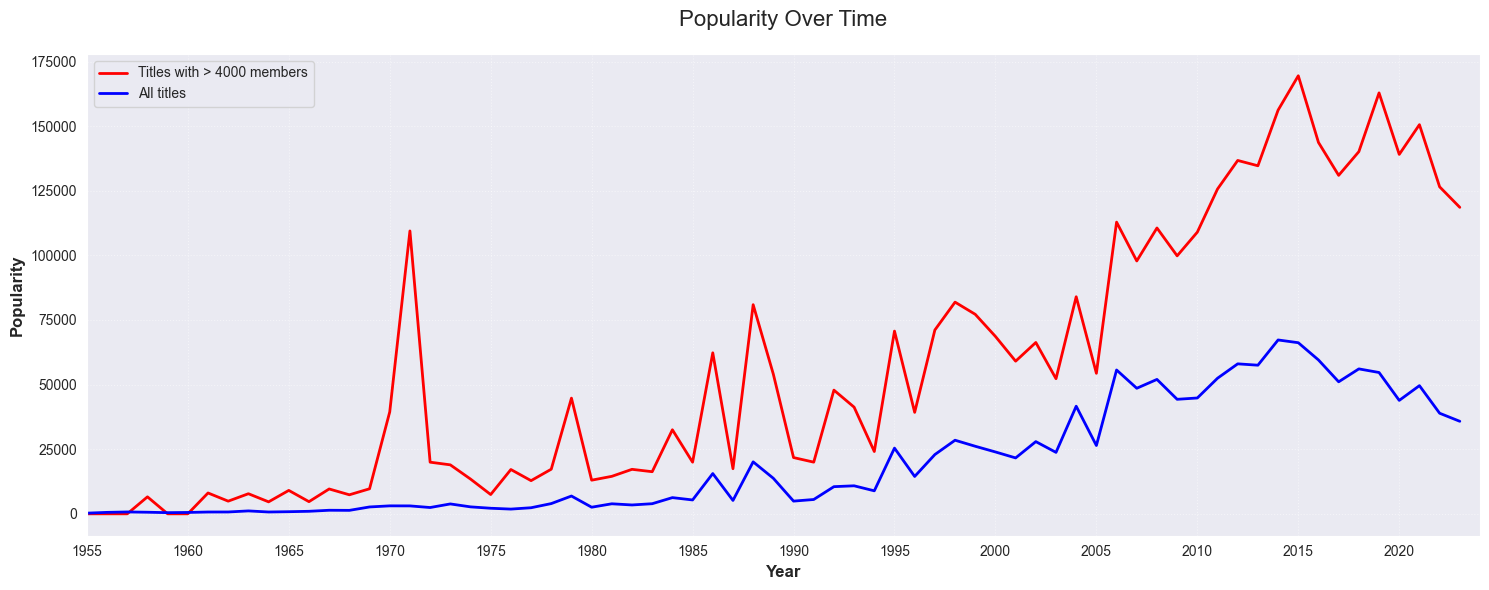

In [47]:
details = df_details.copy()
# popolarità media totale
all_members = (
    details.groupby('year')['members']
    .mean()
    .reindex(range(1955, 2024), fill_value=0)
    .reset_index()
    .rename(columns={'members': 'avg_members'})
)
# popolarità media filtrata
filtered_members = details[details['members'] > 4000]
filtered_members = (
    filtered_members.groupby('year')['members']
    .mean()
    .reindex(range(1955, 2024), fill_value=0)
    .reset_index()
    .rename(columns={'members': 'avg_members'})
)
# creazione grafico
plt.figure(figsize=(15, 6))
plt.grid(linestyle=':', alpha=0.5)
# linee
plt.plot(
    filtered_members['year'],
    filtered_members['avg_members'],
    color='red',
    linewidth=2,
    label='Titles with > 4000 members'
)
plt.plot(
    all_members['year'],
    all_members['avg_members'],
    color='blue',
    linewidth=2,
    label='All titles'
)
# personalizzazione assi
plt.title('Popularity Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Popularity', fontsize=12, fontweight='bold')
plt.xlim(1955, 2024)
plt.xticks(range(1955, 2025, 5))
# legenda
plt.legend()

plt.tight_layout()
plt.show()


Top anime più amati dagli fan

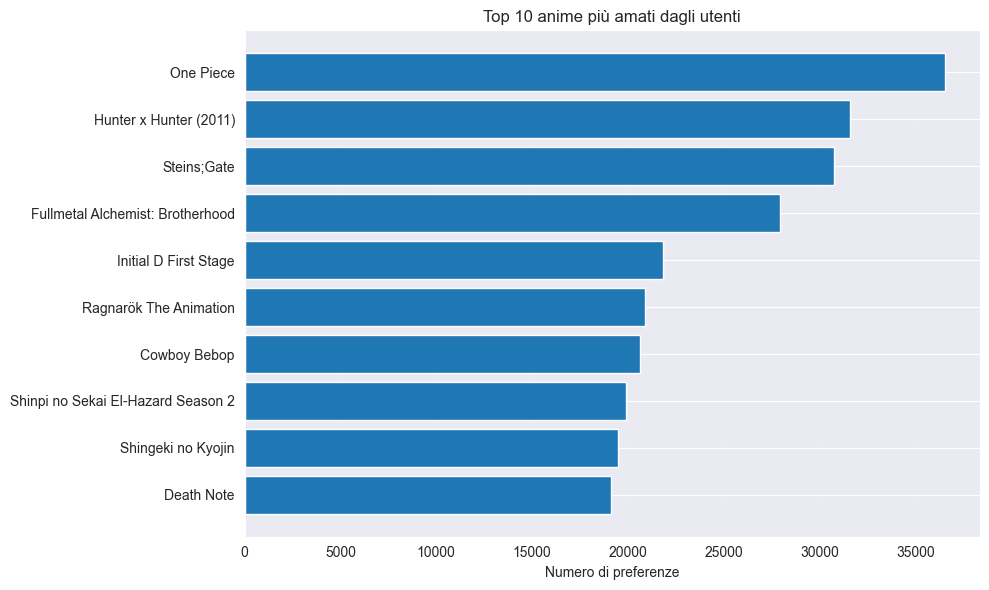

In [48]:
details = df_details.copy()
favs = df_favs.copy()
valid_mal_ids = details['mal_id'].unique()
filtered_favs = favs[favs['mal_id'].isin(valid_mal_ids)]

top_anime = (filtered_favs['mal_id'].value_counts().head(10).reset_index())
top_anime.columns = ['mal_id', 'fav_count']

top_anime = pd.merge(top_anime, details[['mal_id', 'title']], on='mal_id', how='inner')

# Sort for horizontal bar chart
top_anime = top_anime.sort_values('fav_count')

plt.figure(figsize=(10, 6))

plt.barh(top_anime['title'], top_anime['fav_count'])

plt.xlabel("Numero di preferenze")
plt.title("Top 10 anime più amati dagli utenti")
plt.grid(axis='x', alpha=0.1)

plt.tight_layout()
plt.show()

## One Piece: qualità percepita e popolarità tra gli utenti


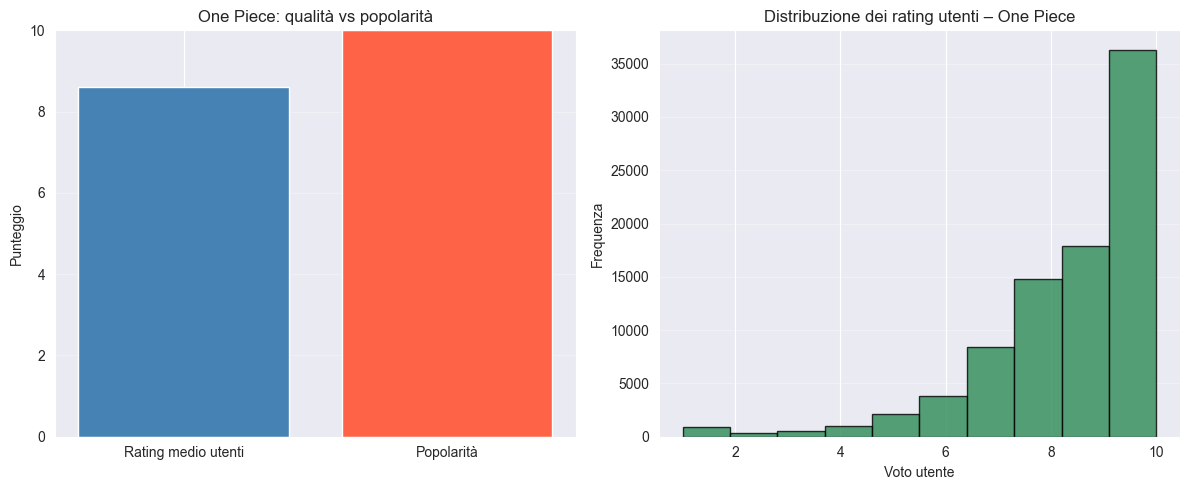

In [49]:
details = df_details.copy()
ratings = df_ratings.copy()
anime_title = "One Piece"
anime_row = details[details["title"] == anime_title]
mal_id = anime_row["mal_id"].iloc[0]
# Rimuoviamo score = 0 (utenti che non hanno votato)
anime_ratings = ratings[
    (ratings["anime_id"] == mal_id) &
    (ratings["score"] > 0)
    ]["score"]
avg_user_rating = anime_ratings.mean()
fav_count = favs[favs["mal_id"] == mal_id].shape[0]
# Normalizzazione favs su scala 0–10
fav_score_norm = (fav_count / favs["mal_id"].value_counts().max()) * 10
# Grafici
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Qualità vs Popolarità
labels = ["Rating medio utenti", "Popolarità"]
values = [avg_user_rating, fav_score_norm]

axes[0].bar(labels, values, color=["steelblue", "tomato"])
axes[0].set_ylim(0, 10)
axes[0].set_ylabel("Punteggio")
axes[0].set_title("One Piece: qualità vs popolarità")
axes[0].grid(axis="y", alpha=0.3)
# Distribuzione rating utenti
axes[1].hist(
    anime_ratings,
    bins=10,
    color="seagreen",
    edgecolor="black",
    alpha=0.8
)
axes[1].set_xlabel("Voto utente")
axes[1].set_ylabel("Frequenza")
axes[1].set_title("Distribuzione dei rating utenti – One Piece")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Questo grafico analizza il caso di **One Piece**, mettendo a confronto la **qualità percepita dagli utenti** (rating medio) e la **popolarità**, misurata tramite il numero di preferenze (favs).

Il primo grafico evidenzia come One Piece presenti una popolarità estremamente elevata, normalizzata su una scala comparabile con il rating. Al contrario, il rating medio degli utenti risulta più moderato. Questo squilibrio suggerisce che la popolarità non dipende esclusivamente dal giudizio medio, ma anche da fattori come la longevità della serie, l’affezione emotiva del pubblico e l’impatto culturale nel tempo.

Il secondo grafico mostra la **distribuzione dei voti degli utenti**. Si osserva una forte concentrazione di voti alti (8–10), accompagnata però da una presenza significativa di voti bassi. Questo fenomeno è tipico delle opere molto popolari: attirano un pubblico ampio e diversificato, generando valutazioni più polarizzate.

Nel complesso, One Piece emerge come un esempio emblematico di come un anime possa essere **massicciamente seguito e amato**, pur non avendo un consenso uniforme sul piano della valutazione numerica.


## Gli anime con il rating più basso: cosa non ha convinto il pubblico

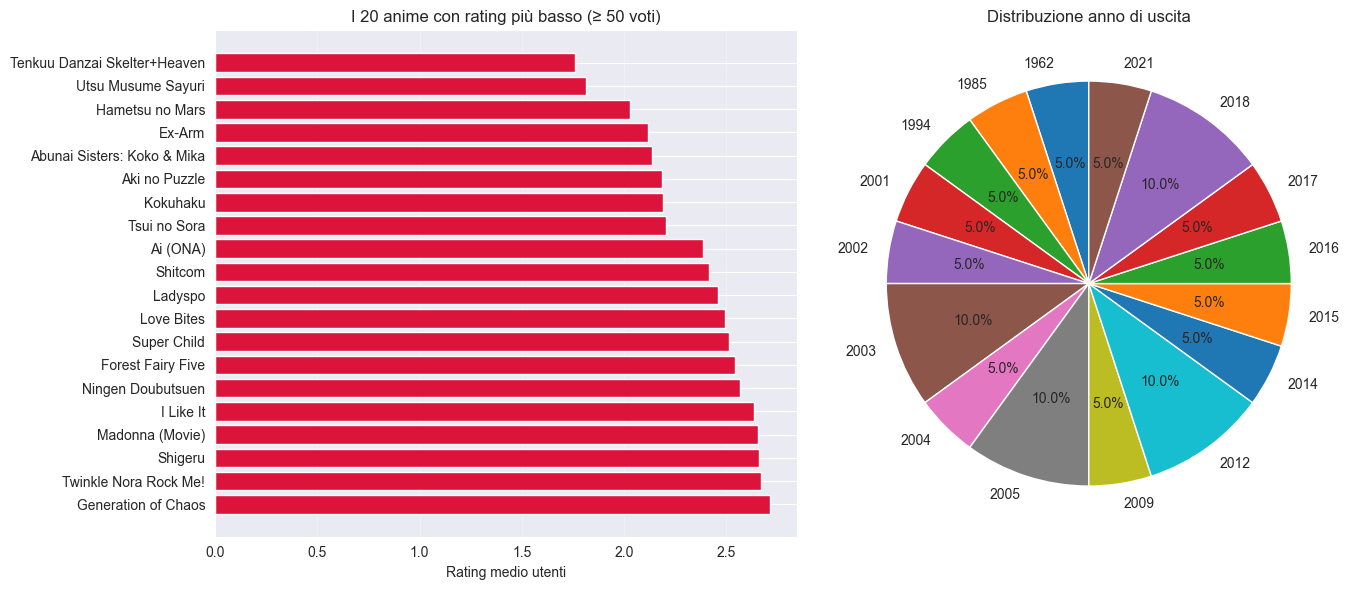

In [50]:
ratings_clean = df_ratings.copy()
ratings_clean = ratings_clean[ratings_clean["score"] > 0]

rating_stats = (
    ratings_clean
    .groupby("anime_id")
    .agg(
        avg_user_score=("score", "mean"),
        num_votes=("score", "count")
    )
    .reset_index()
)

# tieni solo anime con almeno 50 voti
rating_stats = rating_stats[rating_stats["num_votes"] >= 50]

anime_scores = pd.merge(
    rating_stats,
    df_details[["mal_id", "title", "year", "popularity"]],
    left_on="anime_id",
    right_on="mal_id",
    how="inner"
)

# filtro anno SENZA sovrascrivere tutto
anime_scores = anime_scores[
    (anime_scores["year"] >= 1917) &
    (anime_scores["year"] <= 2024)
]

worst_20 = (
    anime_scores
    .sort_values("avg_user_score", ascending=True)
    .head(20)
)

year_counts = worst_20["year"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(
    worst_20["title"],
    worst_20["avg_user_score"],
    color="crimson"
)
axes[0].invert_yaxis()
axes[0].set_xlabel("Rating medio utenti")
axes[0].set_title("I 20 anime con rating più basso (≥ 50 voti)")
axes[0].grid(axis="x", alpha=0.3)

axes[1].pie(
    year_counts.values,
    labels=year_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Distribuzione anno di uscita")

plt.tight_layout()
plt.show()

## Personaggi secondari VS principali degli anime

In [122]:

char_works = df_characters_anime_works.copy()

char_works_clean = (
    char_works[["anime_mal_id", "character_mal_id", "role"]]
    .dropna(subset=["anime_mal_id", "character_mal_id", "role"])
    .copy()
)

char_works_clean["anime_mal_id"] = pd.to_numeric(char_works_clean["anime_mal_id"], errors="coerce")
char_works_clean["character_mal_id"] = pd.to_numeric(char_works_clean["character_mal_id"], errors="coerce")
char_works_clean["role"] = char_works_clean["role"].astype(str).str.strip()

char_works_clean = (
    char_works_clean
    .dropna(subset=["anime_mal_id", "character_mal_id"])
    .drop_duplicates()
)

char_works_clean = char_works_clean[
    char_works_clean["role"].isin(["Main", "Supporting"])
]

# tabella di supporto con i totali
main_support_table = (
    char_works_clean
    .groupby("role")["character_mal_id"]
    .nunique()
    .reset_index(name="total_characters")
)

main_support_table["role"] = main_support_table["role"].replace({
    "Main": "Main",
    "Supporting": "Supporting"
})

main_support_table["percentage"] = (
    main_support_table["total_characters"] /
    main_support_table["total_characters"].sum() * 100
).round(1)

display(main_support_table)

color_map = {
    "Main": "#FFAFCC",
    "Supporting": "#A0C4FF"
}

fig = px.pie(
    main_support_table,
    names="role",
    values="total_characters",
    title="Main vs supporting characters",
    color="role",
    color_discrete_map=color_map,
    hole=0.35
)

fig.update_traces(
    textinfo="percent",
    textposition="outside",
    pull=[0.10, 0]
)

fig.update_layout(
    template="plotly_white",
    width=950,
    height=650,
    title_x=0.5,
    showlegend=True,
    legend_title_text="Character type",
    legend=dict(
        x=1.02,
        y=0.8,
        bgcolor="rgba(255,255,255,0)",
        borderwidth=0
    )
)

fig.show()

,role,total_characters,percentage
0,Main,27686,18.4
1,Supporting,122895,81.6


Questo grafico confronta il numero di personaggi principali e secondari per anime, utilizzando come misura la mediana.


In [118]:

characters = df_characters.copy()
char_works = df_characters_anime_works.copy()

characters_clean = (
    characters[["character_mal_id", "name", "favorites"]]
    .copy()
)

characters_clean["character_mal_id"] = pd.to_numeric(characters_clean["character_mal_id"], errors="coerce")
characters_clean["favorites"] = pd.to_numeric(characters_clean["favorites"], errors="coerce")

characters_clean = (
    characters_clean
    .dropna(subset=["character_mal_id", "favorites"])
    .drop_duplicates(subset=["character_mal_id"])
)

char_works_clean = (
    char_works[["character_mal_id", "role"]]
    .dropna(subset=["character_mal_id", "role"])
    .copy()
)

char_works_clean["character_mal_id"] = pd.to_numeric(char_works_clean["character_mal_id"], errors="coerce")
char_works_clean["role"] = char_works_clean["role"].astype(str).str.strip()

char_works_clean = (
    char_works_clean
    .dropna(subset=["character_mal_id"])
    .query("role in ['Main', 'Supporting']")
    .drop_duplicates()
)

character_role_table = (
    char_works_clean
    .groupby("character_mal_id")["role"]
    .agg(lambda x: "Both" if len(set(x)) == 2 else x.iloc[0])
    .reset_index(name="role_group")
)

character_role_table = character_role_table[
    character_role_table["role_group"].isin(["Main", "Supporting"])
]

character_popularity = pd.merge(
    characters_clean,
    character_role_table,
    on="character_mal_id",
    how="inner"
)

character_popularity["has_favorites"] = character_popularity["favorites"] > 0

control_table = (
    character_popularity
    .groupby("role_group")
    .agg(
        number_of_characters=("character_mal_id", "nunique"),
        total_favorites=("favorites", "sum"),
        characters_with_favorites=("has_favorites", "sum")
    )
    .reset_index()
)

control_table["share_with_favorites"] = (
    control_table["characters_with_favorites"] /
    control_table["number_of_characters"] * 100
).round(1)

display(control_table)

plot_table = (
    control_table[["role_group", "share_with_favorites"]]
    .copy()
    .replace({
        "Main": "Main characters",
        "Supporting": "Supporting characters"
    })
)

color_map = {
    "Main characters": "#FFAFCC",
    "Supporting characters": "#A0C4FF"
}

fig = px.bar(
    plot_table,
    x="role_group",
    y="share_with_favorites",
    color="role_group",
    color_discrete_map=color_map,
    text="share_with_favorites",
    title="Ma i personaggi principali sono anche i preferiti?",
    labels={
        "role_group": "Character type",
        "share_with_favorites": "Characters with at least 1 favourite (%)"
    }
)

fig.update_traces(texttemplate="%{text}%", textposition="outside")

fig.update_layout(
    template="plotly_white",
    width=950,
    height=600,
    showlegend=False,
    title_x=0.5
)

fig.show()

,role_group,number_of_characters,total_favorites,characters_with_favorites,share_with_favorites
0,Main,22322,4925627.0,15666,70.2
1,Supporting,117529,1700847.0,38269,32.6


# I DOPPIATORI NEGLI ANIME

In [112]:
actor_role_table = (
    df_person_voice_works[["person_mal_id", "role"]]
    .dropna()
    .query("role in ['Main', 'Supporting']")
    .drop_duplicates()
    .groupby("person_mal_id")["role"]
    .agg(lambda x: "Both" if len(set(x)) == 2 else f"{x.iloc[0]} only")
    .value_counts()
    .reindex(["Main only", "Supporting only", "Both"], fill_value=0)
    .rename_axis("category")
    .reset_index(name="number_of_voice_actors")
)

actor_role_table

,category,number_of_voice_actors
0,Main only,1674
1,Supporting only,10988
2,Both,9613


## Quanti doppiatori ha ciascuna anima nella top 10?

In [96]:
details = df_details.copy()
favs = df_favs.copy()
voice_works = df_person_voice_works.copy()

valid_mal_ids = details["mal_id"].dropna().unique()
filtered_favs = favs[favs["mal_id"].isin(valid_mal_ids)]

top_anime = (
    filtered_favs["mal_id"]
    .value_counts()
    .head(10)
    .reset_index()
)
top_anime.columns = ["mal_id", "fav_count"]

top_anime = pd.merge(
    top_anime,
    details[["mal_id", "title"]],
    on="mal_id",
    how="inner"
)

voice_works_clean = (
    voice_works[["anime_mal_id", "person_mal_id"]]
    .dropna(subset=["anime_mal_id", "person_mal_id"])
    .copy()
)

voice_works_clean["anime_mal_id"] = pd.to_numeric(voice_works_clean["anime_mal_id"], errors="coerce")
voice_works_clean["person_mal_id"] = pd.to_numeric(voice_works_clean["person_mal_id"], errors="coerce")

voice_works_clean = (
    voice_works_clean
    .dropna(subset=["anime_mal_id", "person_mal_id"])
    .drop_duplicates()
)

voice_actor_counts = (
    voice_works_clean[voice_works_clean["anime_mal_id"].isin(top_anime["mal_id"])]
    .groupby("anime_mal_id")["person_mal_id"]
    .nunique()
    .reset_index(name="distinct_voice_actors")
)

top_anime_voice = pd.merge(
    top_anime,
    voice_actor_counts,
    left_on="mal_id",
    right_on="anime_mal_id",
    how="left"
)

top_anime_voice["distinct_voice_actors"] = (
    top_anime_voice["distinct_voice_actors"]
    .fillna(0)
    .astype(int)
)

pastel_colors = [
    "#A8C5D8",
    "#CDB4DB",
    "#B8E0D2",
    "#FAEDCD",
    "#D6CCC2",
    "#BDE0FE",
    "#E9D8A6",
    "#CCD5AE",
    "#EFC3C5",
    "#C7D3DD"
]

fig = px.pie(
    top_anime_voice,
    names="title",
    values="distinct_voice_actors",
    title="Quanti doppiatori hanno le Top 10 Anime più diffuse",
    color="title",
    color_discrete_sequence=pastel_colors
)

fig.update_traces(
    textinfo="label+value",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    width=1100,
    height=750,
    showlegend=False,
    title_x=0.5
)

fig.show()

Questo grafico mostra quanti doppiatori sono coinvolte per le top 10 anime più diffuse. Notiamo che One Piece emerge rispetto agli altri titoli, con un cast molto numeroso di doppiatori. Questo suggerisce che alcuni degli anime più apprezzati dagli utenti sono anche quelli caratterizzati da una struttura di doppiaggio più complessa e numerosa, mentre altri si basano su un insieme più ristretto di doppiatori.

## Top 10 doppiatori per personaggi distinti doppiati

In [97]:

voice_works = df_person_voice_works.copy()
person_details = df_person_details.copy()

voice_works_clean = (
    voice_works[["person_mal_id", "character_mal_id"]]
    .dropna(subset=["person_mal_id", "character_mal_id"])
    .copy()
)

voice_works_clean["person_mal_id"] = pd.to_numeric(voice_works_clean["person_mal_id"], errors="coerce")
voice_works_clean["character_mal_id"] = pd.to_numeric(voice_works_clean["character_mal_id"], errors="coerce")

voice_works_clean = (
    voice_works_clean
    .dropna(subset=["person_mal_id", "character_mal_id"])
    .drop_duplicates()
)

person_details_clean = (
    person_details[["person_mal_id", "name"]]
    .copy()
)

person_details_clean["person_mal_id"] = pd.to_numeric(person_details_clean["person_mal_id"], errors="coerce")

person_details_clean = (
    person_details_clean
    .dropna(subset=["person_mal_id", "name"])
    .drop_duplicates(subset=["person_mal_id"])
)

top_voice_actors = (
    voice_works_clean
    .groupby("person_mal_id")["character_mal_id"]
    .nunique()
    .reset_index(name="distinct_dubbed_characters")
    .sort_values("distinct_dubbed_characters", ascending=False)
    .head(10)
)

top_voice_actors = pd.merge(
    top_voice_actors,
    person_details_clean,
    on="person_mal_id",
    how="left"
)

top_voice_actors = top_voice_actors.sort_values("distinct_dubbed_characters", ascending=False)
pastel_colors = [
    "#A8C5D8",
    "#CDB4DB",
    "#B8E0D2",
    "#FAEDCD",
    "#D6CCC2",
    "#BDE0FE",
    "#E9D8A6",
    "#CCD5AE",
    "#EFC3C5",
    "#C7D3DD"
]

fig = px.bar(
    top_voice_actors,
    x="distinct_dubbed_characters",
    y="name",
    orientation="h",
    color="name",
    color_discrete_sequence=pastel_colors,
    text="distinct_dubbed_characters",
    title="Top 10 doppiatori per anime distinte doppiate",
    labels={
        "distinct_dubbed_characters": "Number of distinct dubbed characters",
        "name": "Voice actor"
    }
)

fig.update_traces(
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    width=1150,
    height=700,
    showlegend=False,
    title_x=0.5
)

fig.show()

Questo grafico ci permette di individuare i doppiatori più versatili e presenti all’interno dell’industria anime rappresentata nei dati.

# Anime

In [52]:
import pandas as pd
import numpy as np
import plotly.express as px

In [53]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
import pycountry
from plotly.subplots import make_subplots


In [54]:
# load dataset
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")



In [55]:
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")

df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")


# COMMUNITY ANIME

## Distribuzione geografica della community anime

In [56]:
profiles = df_profiles.copy()

# pulizia base di location
profiles["location"] = profiles["location"].astype("string").str.strip()
profiles.loc[
    profiles["location"].str.lower().isin(["", "nan", "none", "unknown"]),
    "location"
] = pd.NA
#estraggo paese (ultimo elemnto dopo virgola)
profiles["country_raw"] = profiles["location"].str.split(",").str[-1].str.strip()

#normalizzazione nomi
country_fix = {
    "Usa": "United States",
    "US": "United States",
    "United States Of America": "United States",
    "UK": "United Kingdom",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "Russian Federation": "Russia",
    "Korea, Republic of": "South Korea",
    "Korea, Rep.": "South Korea",
    "Turkey": "Türkiye",
    "Turkiye": "Türkiye",
    "Türkiye": "Türkiye",

}
profiles["country_clean"] = profiles["country_raw"].replace(country_fix)
profiles["country_clean"] = profiles["country_clean"].where(
    profiles["country_clean"].isna(),
    profiles["country_clean"].str.replace(r"\s+", " ", regex=True).str.strip()
)

# ISO3 mapping
def to_iso3(x):
    if pd.isna(x):
        return pd.NA
    try:
        return pycountry.countries.lookup(x).alpha_3
    except Exception:
        return pd.NA

profiles["iso3"] = profiles["country_clean"].apply(to_iso3)

#controlli utili per verificare che ho preso tutti i paesi
u_total = profiles["username"].nunique()
u_with_location = profiles.loc[profiles["location"].notna(), "username"].nunique()
u_mapped = profiles.loc[profiles["iso3"].notna(), "username"].nunique()

coverage_location = u_with_location / u_total
coverage_iso3_on_total = u_mapped / u_total
coverage_iso3_on_location = u_mapped / u_with_location if u_with_location > 0 else 0

print(f"Unique users total: {u_total:,}")
print(f"Users with location: {u_with_location:,} ({coverage_location:.3f})")
print(f"Users mapped to ISO3: {u_mapped:,} ({coverage_iso3_on_total:.3f} on total users)")
print(f"ISO3 coverage among users with location: {coverage_iso3_on_location:.3f}")

# conteggi unici per paese
country_counts = (
    profiles.dropna(subset=["iso3"])
            .groupby("iso3")["username"]
            .nunique()
            .reset_index(name="n_users")
)
country_counts["log_users"] = np.log10(country_counts["n_users"] + 1)

# mappa
fig = px.choropleth(
    country_counts,
    locations="iso3",
    locationmode="ISO-3",
    color="log_users",
    hover_data={"n_users": True, "log_users": ":.2f"},
    title="Dove si concentra la community del dataset interessata agli anime?"
)
fig.update_layout(
    template="plotly_white",
    width=1100,
    height=600,
    coloraxis_colorbar=dict(title="log10(utenti)", tickformat=".1f")
)
fig.update_geos(showland=True, landcolor="lightgrey", showocean=True, oceancolor="#e6f2ff")
fig.show()

Unique users total: 337,154
Users with location: 337,154 (1.000)
Users mapped to ISO3: 337,154 (1.000 on total users)
ISO3 coverage among users with location: 1.000


La mappa evidenzia paesi in cui il dataset registra una maggiore presenza di utenti appassionati di anime. L'intensità del colore cresce all'aumentare del numero di utenti unici per paese; l'uso della trasformazione log(n_users + 1) comprime le differenze estreme di valore e rende visibili anche paesi con valori più bassi.

#### A questo punto possiamo vedere come l'interesse per gli anime si è sviluppato durante il corso del tempo, considerando i paesi dove esse son maggiormente diffuse.

## I principali poli

In [57]:
country_colors = {
    "Germany": "#636EFA",
    "Argentina": "#EF553B",
    "Japan": "#00CC96",
    "Thailand": "#AB63FA",
    "United Kingdom": "#FFA15A",
    "United States": "#19D3F3"
}

top6_counts = (
    profiles.dropna(subset=["country_clean", "username"])
    .groupby("country_clean")["username"]
    .nunique()
    .sort_values(ascending=False)
    .head(6)
    .reset_index(name="n_users")
)

fig = px.bar(
    top6_counts,
    x="country_clean",
    y="n_users",
    color="country_clean",
    text="n_users",
    title="I principali poli della community anime",
    color_discrete_map=country_colors
)

fig.update_traces(
    texttemplate="%{y:.2s}",
    textposition="outside",
    hovertemplate="<b>%{x}</b><br>Utenti unici: %{y:,}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    width=980,
    height=560,
    xaxis_title="Paese",
    yaxis_title="Utenti unici",
    showlegend=False,
    margin=dict(t=80, l=70, r=30, b=60)
)

fig.update_yaxes(
    tickformat=".2s",
    gridcolor="rgba(0,0,0,0.08)"
)

fig.update_xaxes(
    categoryorder="total descending"
)

fig.show()

La community risulta fortemente concentrata in pochi paesi: Giappone e Stati Uniti emergono come i poli principali, seguiti da un secondo gruppo con valori molto più contenuti.

## Crescita nella community nel tempo

In [58]:
profiles = df_profiles.copy()
# converto joined + extract year
profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year

#uso la stessa logica del grafico precedente
profiles["location"] = profiles["location"].astype("string").str.strip()
profiles.loc[
    profiles["location"].str.lower().isin(["", "nan", "none", "unknown"]),
    "location"
] = pd.NA

profiles["country_raw"] = profiles["location"].str.split(",").str[-1].str.strip()

country_fix = {
    "Usa": "United States",
    "US": "United States",
    "United States Of America": "United States",
    "UK": "United Kingdom",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "Russian Federation": "Russia",
    "Korea, Republic of": "South Korea",
    "Korea, Rep.": "South Korea",
    "Turkey": "Türkiye",
    "Turkiye": "Türkiye",
    "Türkiye": "Türkiye",
}
profiles["country_clean"] = (
    profiles["country_raw"]
    .replace(country_fix)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# filtri sugli anni non sensati
profiles = profiles.dropna(subset=["joined_year", "country_clean"])
profiles = profiles[profiles["joined_year"].between(1995, 2024)]

#top 6 paesi unici
top_countries = (
    profiles.groupby("country_clean")["username"]
            .nunique()
            .sort_values(ascending=False)
            .head(6)
            .index
)

profiles_top = profiles[profiles["country_clean"].isin(top_countries)].copy()

# novi utenti per anno
trend = (
    profiles_top.groupby(["joined_year", "country_clean"])["username"]
                .nunique()
                .reset_index(name="n_users")
)


#line chart
fig = px.line(
    trend,
    x="joined_year",
    y="n_users",
    color="country_clean",
    markers=True,
    title="Crescita della community nel tempo: nuovi utenti registrati per anno (top paesi)"
)

fig.update_layout(
    template="plotly_white",
    width=1100, height=600,
    xaxis_title="Anno",
    yaxis_title="Nuovi utenti" ,
    legend_title_text = "Paese"
)

fig.show()


Il grafico mostra l'andamento dei nuovi utenti registrati ogni anno nei 6 paesi con la maggiore concentrazione di utenti nel dataset. Il Giappone e gli Stati Uniti offrono contributo dominante, mentre gli altri paesi hanno volumi più contenuti ma comunque trend simili.

#### E l'evoluzione a livello globale? Vediamo come si modifica a livello temporale ...

## Crescita della community nel tempo a livello globale

In [59]:
df = df_profiles.copy()
#convert joined to datetime and extract  year
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year

users_per_year = (
    df.dropna(subset=["joined_year"])
      .assign(joined_year=lambda x: x["joined_year"].astype(int))
      .groupby("joined_year", observed=True)["username"]
      .nunique()
      .reset_index(name="new_users")
      .sort_values("joined_year")
)

users_per_year = users_per_year[users_per_year["joined_year"].between(2005, 2024)].copy()

#line chart
fig = px.line(
    users_per_year,
    x="joined_year",
    y="new_users",
    markers=True,
    title="Crescita della community nel tempo: nuovi utenti registrati per anno",
    labels={"joined_year": "Anno", "new_users": "Nuovi utenti"},
)
fig.update_layout(template="plotly_white", width=1100, height=600)
fig.show()

Il grafico mostra l’andamento dei nuovi utenti registrati ogni anno: si osserva una crescita nel tempo, con picchi marcati negli anni più recenti.

## Distribuzione del genere dichiarato dall'utente

In [95]:
import pandas as pd
import plotly.express as px

profiles_copy = profiles.copy()

profiles_copy["gender_clean"] = profiles_copy["gender"].astype(str).str.strip()
profiles_copy["gender_clean"] = profiles_copy["gender_clean"].replace({
    "": pd.NA,
    "nan": pd.NA,
    "NaN": pd.NA,
    "null": pd.NA,
    "Null": pd.NA,
    "NULL": pd.NA,
    "None": pd.NA,
    "none": pd.NA
})

profiles_copy["gender_final"] = profiles_copy["gender_clean"].where(
    profiles_copy["gender_clean"].isin(["Male", "Female"]),
    "Missing / not declared"
)

gender_counts = (
    profiles_copy["gender_final"]
    .value_counts()
    .reindex(["Female", "Male", "Missing / not declared"], fill_value=0)
    .reset_index()
)
gender_counts.columns = ["gender", "count"]

gender_counts["percentage"] = (
    gender_counts["count"] / gender_counts["count"].sum() * 100
).round(1)

display(gender_counts)

color_map = {
    "Female": "#FFAFCC",
    "Male": "#A0C4FF",
    "Missing / not declared": "#D9D9D9"
}

fig = px.pie(
    gender_counts,
    names="gender",
    values="count",
    title="Users gender distribution",
    color="gender",
    color_discrete_map=color_map
)

fig.update_traces(
    textinfo="label+percent",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    width=1000,
    height=700,
    showlegend=False,
    title_x=0.5
)

fig.show()

,gender,count,percentage
0,Female,40527,12.6
1,Male,118733,36.9
2,Missing / not declared,162295,50.5


Nel grafico viene mostrata la quota più ampia che è rappresentata dagli utenti che non hanno dichiarato il loro genere, mentre tra i profili che hanno compilato il campo prevalgono quelli maschili rispetto a quelli femminili.

# PERSONE E RUOLI NELL'INDUSTRIA ANIME

## Da quali paesi provengono le persone che lavorano nell'industria anime

In [90]:
# country da relevant_location
details = df_person_details.copy()

details["country"] = (
    details["relevant_location"]
    .astype("string")
    .str.strip()
    .str.split(",")
    .str[-1]
    .str.strip()
)

country_fix = {
    "Usa": "United States",
    "USA": "United States",
    "United States Of America": "United States",
    "UK": "United Kingdom",
    "U.K.": "United Kingdom",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "Russian Federation": "Russia",
    "Korea, Republic of": "South Korea",
    "Korea, Rep.": "South Korea",
    "Viet Nam": "Vietnam",
    "Türkiye": "Turkey",
    "Turkiye": "Turkey",
}
details["country"] = details["country"].replace(country_fix)

details["country"] = details["country"].where(
    details["country"].isna(),
    details["country"].str.replace(r"\s+", " ", regex=True).str.strip().str.title()
)

# persone uniche x paese
country_counts = (
    details.dropna(subset=["country"])
           .groupby("country")["person_mal_id"]
           .nunique()
           .reset_index(name="n_people")
)

# controllo
valid_countries = set(px.data.gapminder()["country"].unique())

unmapped = country_counts.loc[~country_counts["country"].isin(valid_countries)].copy()
unmapped_people = unmapped["n_people"].sum()
total_people = country_counts["n_people"].sum()

print(f"Paesi presenti nei dati: {len(country_counts)}")
print(f"Paesi NON mappabili (plotly): {len(unmapped)} | persone non mappate: {unmapped_people:,} | coverage persone: {1 - unmapped_people/total_people:.3f}")
print("Esempi paesi non mappati:", unmapped["country"].head(15).tolist())

# present
present_df = country_counts[["country"]].copy()
present_df["present"] = 1

# mappa + bar
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "choropleth"}, {"type": "bar"}]],
    column_widths=[0.58, 0.42],
    subplot_titles=[
        "Paesi con almeno una persona nei credits (presenza)",
        "Numero di persone per paese"
    ]
)

fig.add_trace(
    go.Choropleth(
        locations=present_df["country"],
        locationmode="country names",
        z=present_df["present"],
        colorscale=[(0, "#ffffff"), (1, "#7fd6c2")],
        showscale=False,
        marker_line_color="lightgrey",
        marker_line_width=0.5,
        hovertemplate="Paese=%{location}<extra></extra>"
    ),
    row=1, col=1
)

# Bar chart paesi
bar_df = country_counts.sort_values("n_people", ascending=False).copy()
bar_df["share"] = bar_df["n_people"] / bar_df["n_people"].sum() * 100

fig.add_trace(
    go.Bar(
        x=bar_df["n_people"],
        y=bar_df["country"],
        orientation="h",
        marker_color="#7fd6c2",
        text=(bar_df["share"].round(1).astype(str) + "%"),
        textposition="outside",
        hovertemplate="Paese=%{y}<br>Persone=%{x:,}<br>Quota=%{text}<extra></extra>"
    ),
    row=1, col=2
)

height = min(2000, max(650, 18 * len(bar_df) + 250))  # adatta altezza se ci sono molti paesi

fig.update_layout(
    template="plotly_white",
    width=1200,
    height=height,
    title=dict(text="Distribuzione geografica delle persone nei credits", x=0.01),
    margin=dict(t=80, l=30, r=30, b=30),
)

fig.update_geos(
    showland=True, landcolor="white",
    showcountries=True, countrycolor="lightgrey",
    showocean=True, oceancolor="#f5f7fb"
)

fig.update_yaxes(autorange="reversed", row=1, col=2)
fig.update_xaxes(title_text="Persone uniche", row=1, col=2)

fig.show()

Paesi presenti nei dati: 12
Paesi NON mappabili (plotly): 0 | persone non mappate: 0 | coverage persone: 1.000
Esempi paesi non mappati: []


Il grafico mostra la distribuzione geografica delle persone accreditate nei credits anime. La mappa evidenzia i paesi in cui è presente almeno una persona, mentre il bar chart quantifica il numero di persone uniche per paese, mostrando una forte concentrazione in pochi poli principali.


## Distribuzione Generazionale delle persone che lavorano nell'industria anime

In [91]:
works_people = df_person_anime_works[["person_mal_id"]].copy()
works_people["person_mal_id"] = pd.to_numeric(works_people["person_mal_id"], errors="coerce").astype("Int64")
works_people = works_people.dropna(subset=["person_mal_id"]).drop_duplicates()

details_birth = df_person_details[["person_mal_id", "birthday"]].copy()
details_birth["person_mal_id"] = pd.to_numeric(details_birth["person_mal_id"], errors="coerce").astype("Int64")
details_birth["birthday"] = pd.to_datetime(details_birth["birthday"], errors="coerce", utc=True)
details_birth["birth_year"] = details_birth["birthday"].dt.year.astype("Int64")

details_birth.loc[~details_birth["birth_year"].between(1900, 2024), "birth_year"] = pd.NA
details_birth = details_birth.drop_duplicates(subset=["person_mal_id"])

staff = works_people.merge(
    details_birth[["person_mal_id", "birth_year"]],
    on="person_mal_id",
    how="left"
)

tot_people = staff["person_mal_id"].nunique()
known_people = staff.loc[staff["birth_year"].notna(), "person_mal_id"].nunique()

print(f"Staff in credits: {tot_people:,} unique people")
print(f"Birth year coverage: {known_people/tot_people:.3f} ({known_people:,}/{tot_people:,})")

labels = ["Silent Generation", "Boomers", "Gen X", "Millennials", "Gen Z", "Gen Alpha"]

staff["generation"] = pd.cut(
    staff["birth_year"],
    bins=[-np.inf, 1945, 1964, 1980, 1996, 2012, 2024],
    labels=labels,
    right=True
)

gen_counts = (
    staff.dropna(subset=["generation"])
    .groupby("generation", observed=True)["person_mal_id"]
    .nunique()
    .reset_index(name="count")
)

gen_counts["generation"] = pd.Categorical(gen_counts["generation"], categories=labels, ordered=True)
gen_counts = gen_counts.sort_values("generation")
gen_counts["share"] = gen_counts["count"] / gen_counts["count"].sum() * 100

color_map = {
    "Silent Generation": "#A0AEC0",
    "Boomers": "#F6AD55",
    "Gen X": "#63B3ED",
    "Millennials": "#68D391",
    "Gen Z": "#FC8181",
    "Gen Alpha": "#B794F4",
}

fig = px.bar(
    gen_counts,
    x="generation",
    y="count",
    color="generation",
    color_discrete_map=color_map,
    text=gen_counts["share"].round(1).astype(str) + "%",
    title="Distribuzione generazionale delle persone nei credits anime",
    labels={"count": "Numero di persone", "generation": "Generazione"},
)

fig.update_layout(
    template="plotly_white",
    width=1100,
    height=600,
    showlegend=False
)

fig.update_traces(textposition="outside")
fig.update_yaxes(rangemode="tozero")

fig.show()

Staff in credits: 26,236 unique people
Birth year coverage: 0.244 (6,409/26,236)


Il grafico mostra la distribuzione delle generazioni tra le persone presenti nello staff, ogni barra evidenzia il numero di persone uniche per generazione, con la percentuale calcolata sul sottoinsieme per cui l'anno di nascita è disponibile.


## Dimensione del workforce osservato nei credits anime

In [61]:
works = df_person_anime_works.copy()

works["person_mal_id"] = pd.to_numeric(works["person_mal_id"], errors="coerce")
works["anime_mal_id"] = pd.to_numeric(works["anime_mal_id"], errors="coerce")
works = works.dropna(subset=["person_mal_id", "anime_mal_id"])

n_people = works["person_mal_id"].nunique()
n_links = len(works)

summary_table = pd.DataFrame({
    "Indicatore": [
        "Persone uniche nei credits",
        "Relazioni persona–anime registrate"
    ],
    "Valore": [
        f"{n_people:,}",
        f"{n_links:,}"
    ]
})

summary_table

,Indicatore,Valore
0,Persone uniche nei credits,"26,236"
1,Relazioni persona–anime registrate,"458,091"


## Ruoli più frequenti e notorietà nell'industria anime

In [92]:


works = df_person_anime_works.copy()
details = df_person_details[["person_mal_id", "favorites"]].copy()

# pulizia ruoli
works["position_norm"] = (
    works["position"].astype("string")
    .str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

works.loc[
    works["position_norm"].str.lower().isin(["", "nan", "none", "unknown"]),
    "position_norm"
] = pd.NA

# top 10 ruoli per occorrenze
role_counts = (
    works["position_norm"]
    .dropna()
    .value_counts()
    .reset_index()
)

role_counts.columns = ["role", "occurrences"]
top10 = role_counts.head(10).copy()

# dati notorietà
details["person_mal_id"] = pd.to_numeric(details["person_mal_id"], errors="coerce").astype("Int64")
details["favorites"] = pd.to_numeric(details["favorites"], errors="coerce").fillna(0)
details = details.drop_duplicates(subset=["person_mal_id"])

role_people = (
    works.loc[works["position_norm"].isin(top10["role"]), ["person_mal_id", "position_norm"]]
    .dropna(subset=["person_mal_id", "position_norm"])
    .drop_duplicates()
    .rename(columns={"position_norm": "role"})
    .merge(details, on="person_mal_id", how="left")
)

role_people["favorites"] = role_people["favorites"].fillna(0)

fav_stats = (
    role_people.groupby("role", observed=True)["favorites"]
    .agg(
        people="count",
        share_nonzero=lambda s: (s > 0).mean() * 100
    )
    .reset_index()
)

# merge
top10 = top10.merge(fav_stats, on="role", how="left")

# ordine coerente: per frequenza
top10 = top10.sort_values("occurrences", ascending=True)

# colori coerenti per ruolo
role_color_map = {
    "Key Animation": "#7fd6c2",
    "Animation Director": "#fff7a8",
    "Producer": "#c7c2e0",
    "In-Between Animation": "#ff7f7a",
    "2nd Key Animation": "#7fb3d5",
    "Episode Director": "#f5b041",
    "Planning": "#a8df65",
    "Original Creator": "#f7b6d2",
    "Music": "#d9d9d9",
    "Director": "#af7ac5",
}

bar_colors = top10["role"].map(role_color_map).fillna("#9ecae1")

fig = make_subplots(
    rows=1, cols=2,
    shared_yaxes=True,
    horizontal_spacing=0.12,
    subplot_titles=(
        "Ruoli più diffusi",
        "Notorietà degli stessi ruoli"
    )
)

# grafico sinistro: occorrenze
fig.add_trace(
    go.Bar(
        x=top10["occurrences"],
        y=top10["role"],
        orientation="h",
        marker_color=bar_colors,
        text=top10["occurrences"].map(lambda x: f"{x/1000:.1f}k"),
        textposition="outside",
        hovertemplate="<b>%{y}</b><br>Occorrenze: %{x:,}<extra></extra>",
        showlegend=False
    ),
    row=1, col=1
)

# grafico destro: notorietà
fig.add_trace(
    go.Bar(
        x=top10["share_nonzero"],
        y=top10["role"],
        orientation="h",
        marker_color=bar_colors,
        text=top10["share_nonzero"].map(lambda x: f"{x:.1f}%"),
        textposition="outside",
        hovertemplate="<b>%{y}</b><br>% con favorites > 0: %{x:.1f}%<extra></extra>",
        showlegend=False
    ),
    row=1, col=2
)

fig.update_layout(
    template="plotly_white",
    width=1250,
    height=650,
    title="Ruoli più frequenti e notorietà nell'industria anime"
)

fig.update_xaxes(title_text="Numero di occorrenze", tickformat=".2s", row=1, col=1)
fig.update_xaxes(title_text="% di persone con favorites > 0", ticksuffix="%", row=1, col=2)
fig.update_yaxes(title_text="Ruolo", row=1, col=1)

fig.show()

I due grafici confrontano, per gli stessi 10 ruoli più frequenti nei credits anime, la loro diffusione e la quota di persone associate che risultano selezionate almeno una volta tra i favorites. In questo modo è possibile distinguere i ruoli più presenti nei credits da quelli che risultano anche più riconoscibili.

# COME GLI UTENTI SEGUONO GLI ANIME

## Stato di visione degli anime e come varia nel tempo

In [94]:

profiles = df_profiles.copy()

# anno di iscrizione
profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year

# colonne status
cols = ["watching", "completed", "on_hold", "dropped", "plan_to_watch"]
profiles[cols] = profiles[cols].apply(pd.to_numeric, errors="coerce").fillna(0)

# filtro anni validi
profiles = profiles.dropna(subset=["joined_year"]).copy()
profiles["joined_year"] = profiles["joined_year"].astype(int)
profiles = profiles[profiles["joined_year"].between(2007, 2024)].copy()

# etichette e colori
status_labels = {
    "watching": "Watching",
    "completed": "Completed",
    "on_hold": "On Hold",
    "dropped": "Dropped",
    "plan_to_watch": "Plan to Watch"
}

status_colors = {
    "Watching": "#00CC96",
    "Completed": "#636EFA",
    "On Hold": "#AB63FA",
    "Dropped": "#EF553B",
    "Plan to Watch": "#FFA15A"
}

# Grafico 1:
status_totals = (
    profiles[cols]
    .sum()
    .rename_axis("status")
    .reset_index(name="total")
)

status_totals["status"] = status_totals["status"].replace(status_labels)
status_totals = status_totals.sort_values("total", ascending=True)

fig1 = px.bar(
    status_totals,
    x="total",
    y="status",
    orientation="h",
    color="status",
    color_discrete_map=status_colors,
    text="total",
    title="Stato di visione degli anime"
)

fig1.update_traces(
    texttemplate="%{x:.3s}",
    textposition="outside",
    hovertemplate="<b>%{y}</b><br>Totale: %{x:,}<extra></extra>"
)

fig1.update_layout(
    template="plotly_white",
    width=1100,
    height=500,
    showlegend=False,
    xaxis_title="Totale",
    yaxis_title="Status"
)

fig1.update_xaxes(tickformat=".2s")
fig1.show()


# Grafico 2:
cohort_totals = (
    profiles.groupby("joined_year", observed=True)[cols]
    .sum()
    .reset_index()
    .sort_values("joined_year")
)

den = cohort_totals[cols].sum(axis=1)
cohort_pct = cohort_totals.loc[den > 0].copy()
den = cohort_pct[cols].sum(axis=1)

cohort_pct[cols] = cohort_pct[cols].div(den, axis=0) * 100

cohort_long = cohort_pct.melt(
    id_vars="joined_year",
    value_vars=cols,
    var_name="status",
    value_name="share"
)

cohort_long["status"] = cohort_long["status"].replace(status_labels)

fig2 = px.line(
    cohort_long,
    x="joined_year",
    y="share",
    color="status",
    color_discrete_map=status_colors,
    markers=True,
    title="Come cambia nel tempo lo stato di visione degli anime"
)

fig2.update_traces(
    hovertemplate="<b>%{fullData.name}</b><br>Anno: %{x}<br>Quota: %{y:.1f}%<extra></extra>"
)

fig2.update_layout(
    template="plotly_white",
    width=1100,
    height=600,
    xaxis_title="Anno di iscrizione",
    yaxis_title="Quota sul totale (%)",
    legend_title_text="Status"
)

fig2.update_yaxes(ticksuffix="%", gridcolor="rgba(0,0,0,0.08)")
fig2.show()

Il primo grafico riassume la distribuzione complessiva degli status delle liste anime, mostrando una netta prevalenza di “Completed” e, in secondo luogo, di “Plan to Watch”.

Il secondo grafico confronta la composizione relativa degli status tra utenti iscritti in anni diversi, così da osservare come cambiano le liste senza che la diversa dimensione delle coorti condizioni il confronto.